**imports and connection**

In [1]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect("olist.db")
os.makedirs("charts", exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


**load delivered orders into a DataFrame**

In [2]:
query = """
SELECT o.order_id,
       c.customer_state,
       o.order_delivered_customer_date AS delivered,
       o.order_estimated_delivery_date AS estimated,
       r.review_score
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
LEFT JOIN (SELECT order_id, AVG(review_score) AS review_score
           FROM order_reviews
           GROUP BY order_id) r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
"""
df = pd.read_sql_query(query, conn, parse_dates=["delivered", "estimated"])
print(df.shape)
df.head()

(96470, 5)


,order_id,customer_state,delivered,estimated,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,2017-10-10 21:25:13,2017-10-18,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,BA,2018-08-07 15:27:45,2018-08-13,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,GO,2018-08-17 18:06:29,2018-09-04,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,2017-12-02 00:28:42,2017-12-15,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,2018-02-16 18:17:02,2018-02-26,5.0


**add the late flag and verify against SQL**

In [3]:
df["is_late"] = df["delivered"].dt.normalize() > df["estimated"].dt.normalize()
df["days_vs_estimate"] = (df["delivered"].dt.normalize() - df["estimated"].dt.normalize()).dt.days
print(round(df["is_late"].mean() * 100, 2))   # should be 6.77

6.77


**first chart, review score by delivery status**

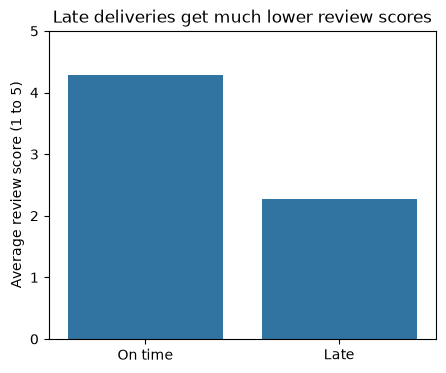

In [4]:
df["delivery_status"] = df["is_late"].map({True: "Late", False: "On time"})

plt.figure(figsize=(5, 4))
sns.barplot(data=df, x="delivery_status", y="review_score", errorbar=None, order=["On time", "Late"])
plt.title("Late deliveries get much lower review scores")
plt.xlabel("")
plt.ylabel("Average review score (1 to 5)")
plt.ylim(0, 5)
plt.savefig("charts/review_by_delivery.png", dpi=150, bbox_inches="tight")
plt.show()